In [1]:
import pandas as pd
import numpy as np
import copy

# Keep the CSV inside your existing data folder
df = pd.read_csv("data/lending_club_loan_two.csv", low_memory=False)

# This dataset has an "address" column, not "addr_state".
# Extract the two-letter state code from the address.
df["addr_state"] = df["address"].str.extract(
    r",\\s*([A-Z]{2})\\s+\\d{5}$", expand=False
).astype("object")

# Replace pandas nullable values with NumPy NaN for scikit-learn compatibility
df["addr_state"] = df["addr_state"].where(
    pd.notna(df["addr_state"]), np.nan
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

df.head()


Dataset loaded successfully!
Shape: (396030, 28)
Columns: ['loan_amnt', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'purpose', 'title', 'dti', 'earliest_cr_line', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'application_type', 'mort_acc', 'pub_rec_bankruptcies', 'address', 'addr_state']


,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,...,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies,address,addr_state
0,10000.0,36 months,11.44,329.48,B,B4,Marketing,10+ years,RENT,117000.0,...,0.0,36369.0,41.8,25.0,w,INDIVIDUAL,0.0,0.0,"0174 Michelle Gateway\r\nMendozaberg, OK 22690",NaN
1,8000.0,36 months,11.99,265.68,B,B5,Credit analyst,4 years,MORTGAGE,65000.0,...,0.0,20131.0,53.3,27.0,f,INDIVIDUAL,3.0,0.0,"1076 Carney Fort Apt. 347\r\nLoganmouth, SD 05113",NaN
2,15600.0,36 months,10.49,506.97,B,B3,Statistician,< 1 year,RENT,43057.0,...,0.0,11987.0,92.2,26.0,f,INDIVIDUAL,0.0,0.0,"87025 Mark Dale Apt. 269\r\nNew Sabrina, WV 05113",NaN
3,7200.0,36 months,6.49,220.65,A,A2,Client Advocate,6 years,RENT,54000.0,...,0.0,5472.0,21.5,13.0,f,INDIVIDUAL,0.0,0.0,"823 Reid Ford\r\nDelacruzside, MA 00813",NaN
4,24375.0,60 months,17.27,609.33,C,C5,Destiny Management Inc.,9 years,MORTGAGE,55000.0,...,0.0,24584.0,69.8,43.0,f,INDIVIDUAL,1.0,0.0,"679 Luna Roads\r\nGreggshire, VA 11650",NaN


In [2]:
# Checking important columns
print("Total columns:", len(df.columns))

print("\nTarget column values:")
print(df["loan_status"].value_counts())

print("\nMissing values:")
print(df[["loan_status", "loan_amnt", "annual_inc", "int_rate", "dti"]].isnull().sum())

print("\nSelected columns:")
df[["loan_amnt", "loan_status", "annual_inc", "int_rate", "dti"]].head()

Total columns: 28

Target column values:
loan_status
Fully Paid     318357
Charged Off     77673
Name: count, dtype: int64

Missing values:
loan_status    0
loan_amnt      0
annual_inc     0
int_rate       0
dti            0
dtype: int64

Selected columns:


,loan_amnt,loan_status,annual_inc,int_rate,dti
0,10000.0,Fully Paid,117000.0,11.44,26.24
1,8000.0,Fully Paid,65000.0,11.99,22.05
2,15600.0,Fully Paid,43057.0,10.49,12.79
3,7200.0,Fully Paid,54000.0,6.49,2.60
4,24375.0,Charged Off,55000.0,17.27,33.95


In [3]:
# Select columns that are available in this Lending Club CSV
features = [
    "loan_amnt",
    "term",
    "int_rate",
    "installment",
    "grade",
    "emp_length",
    "home_ownership",
    "annual_inc",
    "verification_status",
    "purpose",
    "addr_state",
    "dti",
    "open_acc",
    "pub_rec",
    "revol_bal",
    "revol_util",
    "total_acc"
]

# Keep only completed loan outcomes
classification_df = df[
    df["loan_status"].isin(["Fully Paid", "Charged Off"])
][features + ["loan_status"]].copy()

# Convert loan status into binary target
classification_df["target"] = classification_df["loan_status"].map({
    "Fully Paid": 0,
    "Charged Off": 1
})

print("Classification dataset shape:", classification_df.shape)

print("\nTarget distribution:")
print(classification_df["target"].value_counts())
print("\nMissing values in selected columns:")
print(classification_df[features].isnull().sum())


Classification dataset shape: (396030, 19)

Target distribution:
target
0    318357
1     77673
Name: count, dtype: int64

Missing values in selected columns:
loan_amnt                   0
term                        0
int_rate                    0
installment                 0
grade                       0
emp_length              18301
home_ownership              0
annual_inc                  0
verification_status         0
purpose                     0
addr_state             396030
dti                         0
open_acc                    0
pub_rec                     0
revol_bal                   0
revol_util                276
total_acc                   0
dtype: int64


In [4]:
from sklearn.model_selection import train_test_split

# Take 15% sample
classification_sample = classification_df.groupby(
    "target", group_keys=False
).sample(frac=0.15, random_state=42)

# Separate input and output
X = classification_sample[features]
y = classification_sample["target"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

Training shape: (47524, 17)
Testing shape: (11881, 17)

Training target distribution:
target
0    0.803868
1    0.196132
Name: proportion, dtype: float64


In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Work on copies and replace pandas.NA with NumPy NaN.
X_train = X_train.copy()
X_test = X_test.copy()

X_train = X_train.astype({
    col: "object" for col in X_train.select_dtypes(
        include=["object", "string", "category"]
    ).columns
})
X_test = X_test.astype({
    col: "object" for col in X_test.select_dtypes(
        include=["object", "string", "category"]
    ).columns
})

X_train = X_train.replace({pd.NA: np.nan})
X_test = X_test.replace({pd.NA: np.nan})

# Separate numerical and categorical columns
numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=["number"]).columns.tolist()

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Scale numerical data after imputation and combine both pipelines
preprocessor = ColumnTransformer(transformers=[
    ("num", Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numerical columns:", len(numeric_features))
print("Categorical columns:", len(categorical_features))
print("Preprocessing pipeline created successfully!")


Numerical columns: 10
Categorical columns: 7
Preprocessing pipeline created successfully!


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        oob_score=True,
        bootstrap=True,
        n_jobs=-1,
        random_state=42
    )
}

results = {}
trained_pipelines = {}

for name, model in models.items():
    print(f"\\nTraining {name}...")

    model_pipeline = Pipeline(steps=[
        ("preprocessor", copy.deepcopy(preprocessor)),
        ("classifier", model)
    ])

    model_pipeline.fit(X_train, y_train)
    y_pred = model_pipeline.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    results[name] = {
        "Accuracy": accuracy,
        "F1 Score": f1
    }
    trained_pipelines[name] = model_pipeline

    print("Accuracy:", round(accuracy, 4))
    print("F1 Score:", round(f1, 4))

    if name == "Random Forest":
        print("OOB Score:", round(
            model_pipeline.named_steps["classifier"].oob_score_, 4
        ))


\nTraining Logistic Regression...


c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['addr_state']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(
c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['addr_state']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(


Accuracy: 0.8073
F1 Score: 0.1089
\nTraining Decision Tree...


c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['addr_state']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(
c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['addr_state']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(


Accuracy: 0.7892
F1 Score: 0.1795
\nTraining Random Forest...


c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['addr_state']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(


Accuracy: 0.8065
F1 Score: 0.0981
OOB Score: 0.8057


c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['addr_state']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(


In [7]:
# Get the trained Logistic Regression pipeline
logistic_pipeline = trained_pipelines["Logistic Regression"]

# First 5 test rows
probabilities = logistic_pipeline.predict_proba(X_test.iloc[:5])
predictions = logistic_pipeline.predict(X_test.iloc[:5])

# Display comparison
comparison = pd.DataFrame({
    "Actual": y_test.iloc[:5].values,
    "Probability_0": probabilities[:, 0],
    "Probability_1": probabilities[:, 1],
    "Predicted": predictions
})

comparison


c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['addr_state']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(
c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['addr_state']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(


,Actual,Probability_0,Probability_1,Predicted
0,1,0.444555,0.555445,1
1,0,0.952976,0.047024,0
2,1,0.772531,0.227469,0
3,0,0.625639,0.374361,0
4,0,0.882682,0.117318,0


In [8]:
# Get feature names after preprocessing
random_forest_pipeline = trained_pipelines["Random Forest"]
feature_names = random_forest_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get Random Forest feature importance
forest_importance = random_forest_pipeline.named_steps[
    "classifier"
].feature_importances_

# Display top 5 features
forest_top5 = pd.DataFrame({
    "Feature": feature_names,
    "Importance": forest_importance
}).sort_values(by="Importance", ascending=False).head(5)

forest_top5


,Feature,Importance
1,num__int_rate,0.114919
4,num__dti,0.095334
3,num__annual_inc,0.085456
7,num__revol_bal,0.072983
8,num__revol_util,0.072265


In [9]:
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

# Create validation data from the training data
X_train_xgb, X_val, y_train_xgb, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Fit preprocessing only on the XGBoost training split
xgb_preprocessor = copy.deepcopy(preprocessor)
X_train_processed = xgb_preprocessor.fit_transform(X_train_xgb)
X_val_processed = xgb_preprocessor.transform(X_val)
X_test_processed = xgb_preprocessor.transform(X_test)

# Create and train XGBoost
xgb_model = XGBClassifier(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.05,
    early_stopping_rounds=20,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(
    X_train_processed,
    y_train_xgb,
    eval_set=[(X_val_processed, y_val)],
    verbose=False
)

# Evaluate on test data
xgb_predictions = xgb_model.predict(X_test_processed)

xgb_accuracy = accuracy_score(y_test, xgb_predictions)
xgb_f1 = f1_score(y_test, xgb_predictions, zero_division=0)

results["XGBoost"] = {
    "Accuracy": xgb_accuracy,
    "F1 Score": xgb_f1
}

print("XGBoost Accuracy:", round(xgb_accuracy, 4))
print("XGBoost F1 Score:", round(xgb_f1, 4))
print("Best iteration:", xgb_model.best_iteration)


c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['addr_state']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(
c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['addr_state']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(
c:\Users\ADMIN\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\impute\_base.py:647: UserWarning: Skipping features without any observed values: ['addr_state']. At least one non-missing value is needed for imputation with strategy='constant'.
  warnings.warn(


XGBoost Accuracy: 0.8058
XGBoost F1 Score: 0.0834
Best iteration: 80


In [10]:
xgb_importance = xgb_model.feature_importances_

xgb_top5 = pd.DataFrame({
    "Feature": xgb_preprocessor.get_feature_names_out(),
    "Importance": xgb_importance
}).sort_values(
    by="Importance",
    ascending=False
).head(5)

xgb_top5


,Feature,Importance
1,num__int_rate,0.131349
10,cat__term_ 36 months,0.108576
14,cat__grade_C,0.108158
15,cat__grade_D,0.050728
13,cat__grade_B,0.043944


In [11]:
regression_features = [
    "annual_inc",
    "int_rate",
    "dti",
    "open_acc",
    "pub_rec",
    "revol_bal",
    "total_acc"
]

regression_df = df[regression_features + ["loan_amnt"]].copy()

# Convert selected columns to numeric values
for col in regression_df.columns:
    regression_df[col] = pd.to_numeric(
        regression_df[col], errors="coerce"
    )

# Remove rows where the target is missing
regression_df = regression_df.dropna(subset=["loan_amnt"])

# Take a reproducible 15% sample
regression_df = regression_df.sample(
    frac=0.15, random_state=42
)

X_reg = regression_df[regression_features]
y_reg = regression_df["loan_amnt"]

print("Dataset shape:", regression_df.shape)
print("Missing values:")
print(regression_df.isnull().sum())


Dataset shape: (59404, 8)
Missing values:
annual_inc    0
int_rate      0
dti           0
open_acc      0
pub_rec       0
revol_bal     0
total_acc     0
loan_amnt     0
dtype: int64


In [12]:
from sklearn.model_selection import train_test_split

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train_reg.shape)
print("Testing data:", X_test_reg.shape)

Training data: (47523, 7)
Testing data: (11881, 7)


In [13]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

reg_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_train_processed = reg_preprocessor.fit_transform(X_train_reg)
X_test_processed = reg_preprocessor.transform(X_test_reg)

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

Training shape: (47523, 7)
Testing shape: (11881, 7)


In [14]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import r2_score, mean_absolute_error
import pandas as pd

reg_models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=1.0)
}

reg_results = {}

for name, model in reg_models.items():
    model.fit(X_train_processed, y_train_reg)

    y_pred = model.predict(X_test_processed)

    r2 = r2_score(y_test_reg, y_pred)
    mae = mean_absolute_error(y_test_reg, y_pred)

    reg_results[name] = {
        "R2 Score": r2,
        "MAE": mae
    }

    print(name)
    print("R2 Score:", r2)
    print("MAE:", mae)
    print("-" * 30)

Linear Regression
R2 Score: 0.2352403782898167
MAE: 5752.024722135865
------------------------------
Ridge
R2 Score: 0.23523987970603588
MAE: 5752.032825443428
------------------------------
Lasso
R2 Score: 0.23522647784206585
MAE: 5752.21920796737
------------------------------


In [15]:
coefficient_comparison = pd.DataFrame({
    "Feature": regression_features,
    "Linear Regression": reg_models["Linear Regression"].coef_,
    "Ridge": reg_models["Ridge"].coef_,
    "Lasso": reg_models["Lasso"].coef_
})

print(coefficient_comparison)

zero_count = sum(
    abs(reg_models["Lasso"].coef_) < 1e-5
)

print("\nLasso zero coefficients:", zero_count)

      Feature  Linear Regression        Ridge        Lasso
0  annual_inc        1686.775095  1686.752337  1686.372871
1    int_rate        1686.069864  1686.027684  1684.657389
2         dti        -305.890297  -305.873292  -304.156973
3    open_acc         338.658103   338.680098   337.907265
4     pub_rec        -610.469130  -610.456011  -609.380527
5   revol_bal        2058.321506  2058.283587  2057.588567
6   total_acc        1092.241635  1092.208295  1091.470488

Lasso zero coefficients: 0


In [16]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

cluster_features = ["loan_amnt", "annual_inc", "dti"]

cluster_df = df[cluster_features].copy()

# Use at most 10,000 rows
cluster_df = cluster_df.sample(
    n=min(10000, len(cluster_df)), random_state=42
)

cluster_df = cluster_df.apply(
    pd.to_numeric, errors="coerce"
)

cluster_df = cluster_df.fillna(
    cluster_df.median()
)

cluster_scaled = StandardScaler().fit_transform(cluster_df)

print("Clustering data shape:", cluster_scaled.shape)
print("Missing values:", cluster_df.isnull().sum().sum())


Clustering data shape: (10000, 3)
Missing values: 0


In [17]:
inertia_values = []
silhouette_values = []

for k in range(2, 9):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(cluster_scaled)

    inertia_values.append(kmeans.inertia_)

    score = silhouette_score(
        cluster_scaled, labels
    )

    silhouette_values.append(score)

    print(
        f"K = {k}, "
        f"Inertia = {kmeans.inertia_:.2f}, "
        f"Silhouette Score = {score:.4f}"
    )

K = 2, Inertia = 21472.39, Silhouette Score = 0.3408
K = 3, Inertia = 16017.04, Silhouette Score = 0.3165
K = 4, Inertia = 13412.20, Silhouette Score = 0.3259
K = 5, Inertia = 11670.69, Silhouette Score = 0.3131
K = 6, Inertia = 10261.79, Silhouette Score = 0.2934
K = 7, Inertia = 9073.97, Silhouette Score = 0.2603
K = 8, Inertia = 8113.74, Silhouette Score = 0.2619


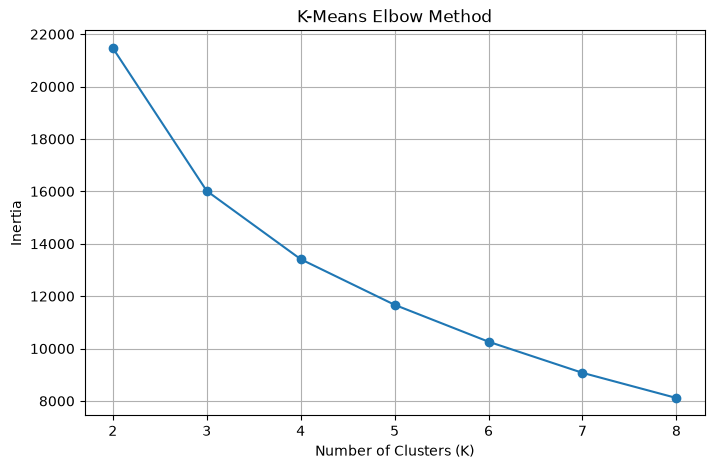

In [18]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 9),
    inertia_values,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Method")
plt.xticks(range(2, 9))
plt.grid(True)
plt.show()

In [19]:
# Remove unusual DTI values
clean_cluster_df = cluster_df[
    (cluster_df["dti"] <= 100) &
    (cluster_df["annual_inc"] > 0)
].copy()

# Scale again
cluster_scaled_clean = StandardScaler().fit_transform(
    clean_cluster_df[cluster_features]
)

# Create 3 clusters again
final_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

clean_cluster_df["Cluster"] = final_kmeans.fit_predict(
    cluster_scaled_clean
)

# Display segment summary
print(
    clean_cluster_df.groupby("Cluster")[
        cluster_features
    ].mean().round(2)
)

print("\nCluster counts:")
print(clean_cluster_df["Cluster"].value_counts().sort_index())

         loan_amnt  annual_inc    dti
Cluster                              
0          9655.18    63791.13  11.63
1         25608.19   121253.38  15.62
2         12115.13    54865.93  25.71

Cluster counts:
Cluster
0    4312
1    2264
2    3424
Name: count, dtype: int64


In [20]:
print("XGBoost Results:")
print("Accuracy:", round(results["XGBoost"]["Accuracy"], 4))
print("F1 Score:", round(results["XGBoost"]["F1 Score"], 4))
print("Best Iteration:", xgb_model.best_iteration)


XGBoost Results:
Accuracy: 0.8058
F1 Score: 0.0834
Best Iteration: 80


In [21]:
classification_results = pd.DataFrame([
    {
        "Model": model_name,
        "Accuracy": metrics["Accuracy"],
        "F1 Score": metrics["F1 Score"]
    }
    for model_name, metrics in results.items()
])

classification_results = classification_results.sort_values(
    by="Accuracy", ascending=False
).reset_index(drop=True)

print("Classification model comparison:")
display(classification_results)

print("\nBest model by Accuracy:")
print(classification_results.loc[0, "Model"])


Classification model comparison:


,Model,Accuracy,F1 Score
0,Logistic Regression,0.807255,0.108949
1,Random Forest,0.806498,0.098078
2,XGBoost,0.805824,0.083433
3,Decision Tree,0.789159,0.179496



Best model by Accuracy:
Logistic Regression



## Classification
- Prepared the target using completed loan outcomes: Fully Paid and Charged Off.
- Trained Logistic Regression, Decision Tree, Random Forest and XGBoost classifiers.
- Compared the models using Accuracy and F1 Score.
- The exact scores are displayed in the Classification Model Comparison table above.

## Regression
- Trained Linear Regression, Ridge and Lasso models to predict loan amount.
- Compared the models using R² Score and Mean Absolute Error (MAE).
- The exact scores are displayed in the regression results above.

## Clustering
- Applied K-Means clustering using loan amount, annual income and DTI.
- Tested different cluster counts using inertia and silhouette score.
- Reviewed the final three customer segments using their average feature values.

## Conclusion
This assessment covers supervised classification, regression and unsupervised clustering using the Lending Club loan dataset. Model performance and customer segments are evaluated from the results generated by running this notebook.
